# Chapter 7: Support Vector Machines and Kernel Methods

**Book:** scikit-learn Cookbook, Third Edition  
**Author:** John Sukup

## Learning Objectives

After completing this chapter, we will be able to:

1. Understand the basic concepts of Support Vector Machines (SVM).
2. Train an SVM classifier using scikit-learn.
3. Understand kernel functions and their applications.
4. Tune SVM hyperparameters.
5. Apply SVM to high-dimensional data.
6. Evaluate SVM classification models.

## Table of Contents

1. Introduction to SVMs
2. Kernel Functions and Their Applications
3. Tuning SVM Parameters
4. SVMs in High-Dimensional Spaces
5. Evaluating SVM Models
6. Practical Exercises
7. Summary

## Technical Requirements

This chapter uses Python and the following libraries:

- NumPy for numerical calculations.
- pandas for data organization.
- Matplotlib and Seaborn for visualization.
- scikit-learn for datasets, model training, and evaluation.

The examples use built-in datasets and synthetic data generated by scikit-learn.

All code is designed for Google Colab or Jupyter Notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Introduction to Support Vector Machines

Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification and regression. In this chapter, we focus on classification.

SVM attempts to find a decision boundary that separates classes. In a binary classification problem, this boundary is called a hyperplane.

The main concepts are:

- **Hyperplane:** The decision boundary separating classes.
- **Support vectors:** Data points closest to the decision boundary.
- **Margin:** The distance between the decision boundary and the nearest data points from each class.
- **C parameter:** Controls the trade-off between a wider margin and classification errors.

SVM attempts to find a boundary with a large margin while controlling classification errors. The best choice of parameters depends on the dataset.

In [2]:
# Load the Breast Cancer dataset
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Feature names:", data.feature_names[:5])
print("Class names:", data.target_names)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Dataset shape: (569, 30)
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']
Class names: ['malignant' 'benign']

Training samples: 455
Testing samples: 114


In [3]:
# Scale the features before training SVM
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])

svm_pipeline.fit(X_train, y_train)

y_pred = svm_pipeline.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)

Accuracy: 0.9737

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.98      0.96        42
      benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



### How It Works

The dataset is divided into training and testing sets. StandardScaler is used to standardize the features because SVM can be sensitive to differences in feature scales.

The SVM classifier then learns a linear decision boundary from the training data.

The `predict()` method generates predictions for the testing data. Accuracy and the classification report are used to evaluate the results.

The reported scores describe this particular data split and model configuration; they are not guaranteed results for every experiment.

## 2. Kernel Functions and Their Applications

A linear decision boundary may not be suitable for every dataset. Some classes can have nonlinear relationships that cannot be separated well by a straight line.

SVM uses kernel functions to model more complex decision boundaries without explicitly calculating every transformation into a higher-dimensional feature space.

Common kernel functions include:

- **Linear:** Suitable when the classes can be separated approximately by a linear boundary.
- **Polynomial:** Models relationships involving polynomial combinations of features.
- **RBF (Radial Basis Function):** Can represent flexible nonlinear decision boundaries.
- **Sigmoid:** Uses a sigmoid-shaped kernel function and can behave similarly to certain neural-network activation forms.

The appropriate kernel depends on the structure of the data and should be selected through evaluation rather than assumption.

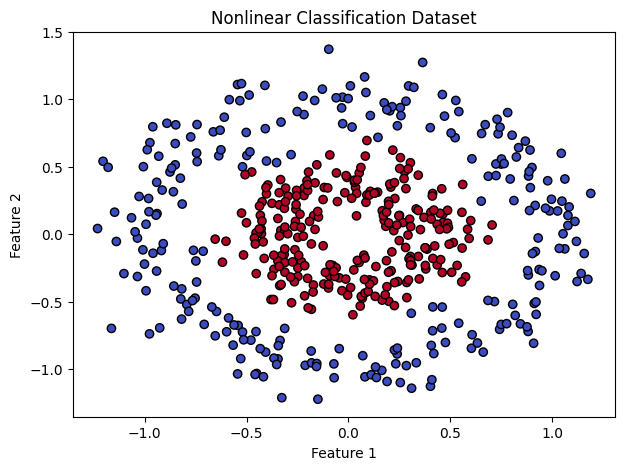

In [4]:
from sklearn.datasets import make_circles

X_circle, y_circle = make_circles(
    n_samples=500,
    noise=0.12,
    factor=0.4,
    random_state=42
)

plt.figure(figsize=(7, 5))

plt.scatter(
    X_circle[:, 0],
    X_circle[:, 1],
    c=y_circle,
    cmap="coolwarm",
    edgecolors="black"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Classification Dataset")
plt.show()

In [7]:
X_train_circle, X_test_circle, y_train_circle, y_test_circle = (
    train_test_split(
        X_circle,
        y_circle,
        test_size=0.25,
        random_state=42,
        stratify=y_circle
    )
)

kernels = ["linear", "poly", "rbf", "sigmoid"]
kernel_results = []

for kernel in kernels:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel=kernel, C=1.0))
    ])

    model.fit(X_train_circle, y_train_circle)
    predictions = model.predict(X_test_circle)

    score = accuracy_score(y_test_circle, predictions)

    kernel_results.append({
        "Kernel": kernel,
        "Accuracy": score
    })

kernel_results_df = pd.DataFrame(kernel_results)
display(kernel_results_df.sort_values("Accuracy", ascending=False))

,Kernel,Accuracy
2,rbf,0.976
1,poly,0.624
3,sigmoid,0.624
0,linear,0.552


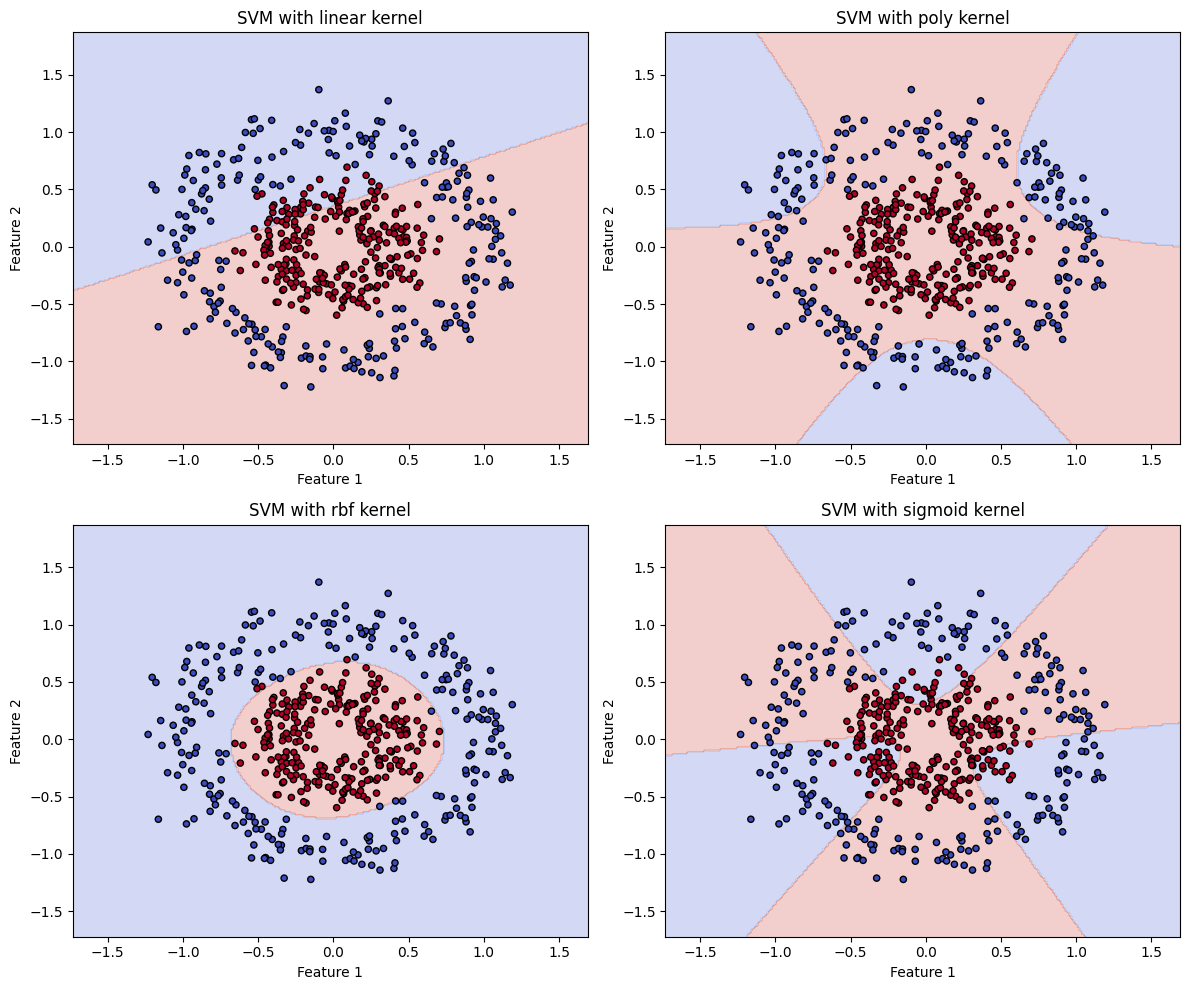

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, kernel in zip(axes.ravel(), kernels):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel=kernel, C=1.0))
    ])

    model.fit(X_train_circle, y_train_circle)

    x_min, x_max = X_circle[:, 0].min() - 0.5, X_circle[:, 0].max() + 0.5
    y_min, y_max = X_circle[:, 1].min() - 0.5, X_circle[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    ax.scatter(
        X_circle[:, 0],
        X_circle[:, 1],
        c=y_circle,
        cmap="coolwarm",
        edgecolors="black",
        s=20
    )

    ax.set_title(f"SVM with {kernel} kernel")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()


### How It Works

The generated dataset contains two classes arranged in a circular pattern. A linear boundary may struggle to separate them because the classes have a nonlinear relationship.

Each SVM model uses a different kernel function. The comparison table reports its accuracy on the same testing set.

The decision-boundary plots show how each kernel separates the classes. The RBF kernel often works well for circular patterns, but performance still depends on the dataset, noise, and hyperparameter settings.

The purpose of this experiment is to demonstrate why kernel selection matters, not to assume that one kernel is always the best.

## 3. Tuning SVM Parameters

SVM performance can change depending on the values of its hyperparameters.

Important parameters include:

- **C:** Controls the penalty for classification errors. A larger value generally penalizes errors more strongly, while a smaller value allows more violations of the margin.
- **kernel:** Determines the type of decision boundary.
- **gamma:** Controls the influence of individual training samples for kernels such as RBF.
- **degree:** Determines the polynomial degree when using a polynomial kernel.

GridSearchCV can systematically evaluate multiple parameter combinations using cross-validation.

Hyperparameter tuning should be performed using training data. The testing set should be reserved for final evaluation to avoid biased performance estimates.

In [9]:
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.01, 0.1, 1],
    "svm__kernel": ["rbf", "linear"]
}

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_, 4))

Best Parameters:
{'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}

Best Cross-Validation Accuracy:
0.9802


In [10]:
best_svm = grid_search.best_estimator_

y_pred_tuned = best_svm.predict(X_test)

print(
    "Test Accuracy:",
    round(accuracy_score(y_test, y_pred_tuned), 4)
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_tuned,
        target_names=data.target_names
    )
)

Test Accuracy: 0.9825

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### How It Works

GridSearchCV tests the specified combinations of SVM parameters using five-fold cross-validation on the training data.

The `best_params_` attribute returns the parameter combination with the best mean cross-validation score.

The `best_estimator_` attribute provides the model fitted using the selected parameters. We evaluate that model on the separate testing set.

The best cross-validation score and final testing accuracy may differ because they are calculated on different data partitions.

## 4. SVMs in High-Dimensional Spaces

High-dimensional datasets contain many features. For example, a text dataset may represent each document using thousands of word-related features.

SVM can be useful in high-dimensional spaces because its decision boundary is determined by support vectors and the selected kernel.

However, having many features does not automatically guarantee good performance. Irrelevant features, insufficient training data, and poorly selected parameters can still reduce model quality.

Feature scaling and appropriate model validation remain important when training SVM on high-dimensional data.

In [11]:
X_high, y_high = make_classification(
    n_samples=1000,
    n_features=100,
    n_informative=20,
    n_redundant=10,
    n_repeated=0,
    n_classes=2,
    random_state=42
)

X_train_high, X_test_high, y_train_high, y_test_high = (
    train_test_split(
        X_high,
        y_high,
        test_size=0.2,
        random_state=42,
        stratify=y_high
    )
)

print("Number of samples:", X_high.shape[0])
print("Number of features:", X_high.shape[1])

Number of samples: 1000
Number of features: 100


In [12]:
high_dim_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1.0))
])

high_dim_svm.fit(X_train_high, y_train_high)

y_pred_high = high_dim_svm.predict(X_test_high)

print(
    "High-Dimensional SVM Accuracy:",
    round(accuracy_score(y_test_high, y_pred_high), 4)
)

print("\nClassification Report:")
print(classification_report(y_test_high, y_pred_high))

High-Dimensional SVM Accuracy: 0.77

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.79      0.73      0.76       100

    accuracy                           0.77       200
   macro avg       0.77      0.77      0.77       200
weighted avg       0.77      0.77      0.77       200



### How It Works

The synthetic dataset contains 100 numerical features for each observation.

The pipeline standardizes the features before training a linear SVM. After training, the model predicts labels for the testing data.

This experiment demonstrates the SVM workflow for high-dimensional data. It does not establish that SVM will outperform other algorithms on every high-dimensional dataset.

## 5. Evaluating SVM Models

Evaluating an SVM model helps determine how well it classifies unseen observations.

Common evaluation tools include:

- **Accuracy:** The proportion of correct predictions.
- **Precision:** How many predicted positive cases are actually positive.
- **Recall:** How many actual positive cases are identified.
- **F1-score:** A combined measure of precision and recall.
- **Confusion matrix:** Shows correct and incorrect predictions for each class.
- **ROC curve and AUC:** Evaluate the trade-off between true positive rate and false positive rate across thresholds.

No single metric is suitable for every problem. The evaluation strategy should reflect the consequences of different classification errors.

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



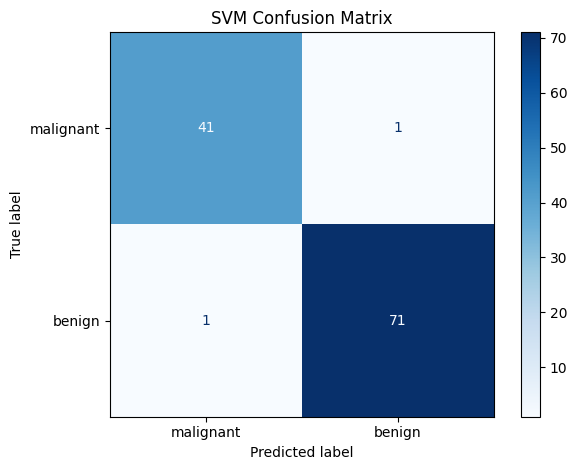

In [13]:
evaluation_model = best_svm
y_pred_eval = evaluation_model.predict(X_test)

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred_eval,
        target_names=data.target_names
    )
)

ConfusionMatrixDisplay.from_estimator(
    evaluation_model,
    X_test,
    y_test,
    display_labels=data.target_names,
    cmap="Blues"
)

plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()

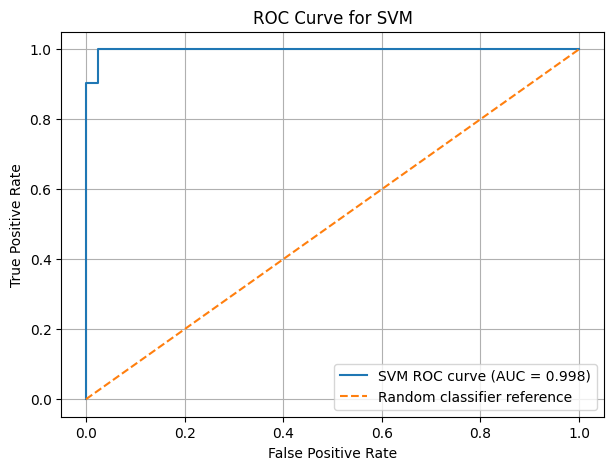

ROC AUC: 0.9977


In [14]:
# SVC uses decision scores for ROC analysis
y_scores = evaluation_model.decision_function(X_test)

fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"SVM ROC curve (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier reference"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for SVM")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print("ROC AUC:", round(roc_auc, 4))

### How It Works

The confusion matrix shows the number of correct and incorrect predictions for each class.

The classification report provides precision, recall, and F1-score. These metrics can reveal weaknesses that are not obvious from accuracy alone.

For an SVC model, `decision_function()` returns decision scores. These scores can be used to construct an ROC curve and calculate AUC.

AUC summarizes how well the model ranks positive observations above negative observations across decision thresholds. It should be interpreted alongside other metrics and the requirements of the problem.

## 6. Practical Exercises

### Exercise 1: Building a Simple SVM Classifier

Train an SVM classifier on a classification dataset. Evaluate its accuracy and classification report.

### Exercise 2: Tuning SVM Parameters with Grid Search

Use GridSearchCV to find suitable values for C and gamma. Compare cross-validation performance with final testing performance.

### Exercise 3: Visualizing SVM Decision Boundaries

Generate a two-dimensional dataset and compare the decision boundaries produced by linear and RBF kernels.

These exercises are adapted practice tasks based on the chapter topics.

In [15]:
simple_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0))
])

simple_svm.fit(X_train_circle, y_train_circle)

simple_pred = simple_svm.predict(X_test_circle)

print(
    "Accuracy:",
    round(accuracy_score(y_test_circle, simple_pred), 4)
)

print(classification_report(y_test_circle, simple_pred))

Accuracy: 0.976
              precision    recall  f1-score   support

           0       0.95      1.00      0.98        63
           1       1.00      0.95      0.98        62

    accuracy                           0.98       125
   macro avg       0.98      0.98      0.98       125
weighted avg       0.98      0.98      0.98       125



In [16]:
exercise_grid = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC())
    ]),
    param_grid={
        "svm__C": [0.1, 1, 10],
        "svm__gamma": ["scale", 0.01, 0.1],
        "svm__kernel": ["rbf"]
    },
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

exercise_grid.fit(X_train_circle, y_train_circle)

print("Best parameters:", exercise_grid.best_params_)
print("Best CV accuracy:", round(exercise_grid.best_score_, 4))

exercise_pred = exercise_grid.predict(X_test_circle)

print(
    "Test accuracy:",
    round(accuracy_score(y_test_circle, exercise_pred), 4)
)

Best parameters: {'svm__C': 1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Best CV accuracy: 0.9893
Test accuracy: 0.976


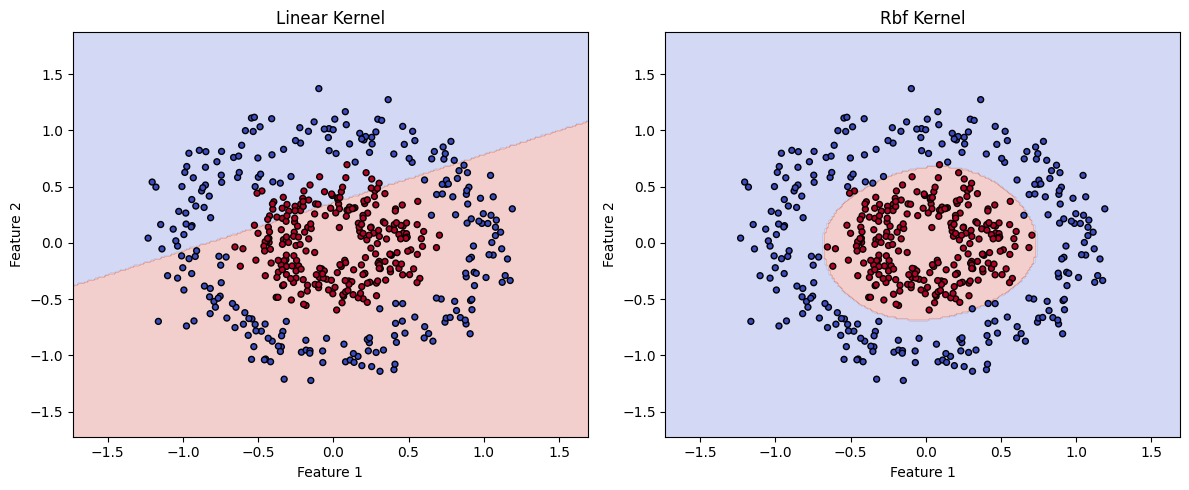

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, kernel in zip(axes, ["linear", "rbf"]):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel=kernel, C=1.0))
    ])

    model.fit(X_train_circle, y_train_circle)

    x_min, x_max = X_circle[:, 0].min() - 0.5, X_circle[:, 0].max() + 0.5
    y_min, y_max = X_circle[:, 1].min() - 0.5, X_circle[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    ax.scatter(
        X_circle[:, 0],
        X_circle[:, 1],
        c=y_circle,
        cmap="coolwarm",
        edgecolors="black",
        s=18
    )

    ax.set_title(f"{kernel.capitalize()} Kernel")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

## 7. Summary

This chapter introduced Support Vector Machines and kernel methods for classification.

The main concepts covered were:

1. **Support Vector Machines:** SVM finds a decision boundary that separates classes while balancing the margin and classification errors.
2. **Kernel functions:** Linear, polynomial, RBF, and sigmoid kernels provide different ways to model relationships in data.
3. **Hyperparameter tuning:** Parameters such as C and gamma can be selected using cross-validation and grid search.
4. **High-dimensional data:** SVM can be applied to datasets with many features, although scaling and model validation remain important.
5. **Model evaluation:** Accuracy, precision, recall, F1-score, confusion matrices, ROC curves, and AUC help assess model performance.

The practical examples demonstrated how to prepare data, train SVM models, compare kernels, tune hyperparameters, visualize decision boundaries, and evaluate predictions.

The most appropriate SVM configuration depends on the dataset and the objective of the classification task.